# Prédiction du risque de défaut sur la base « Crédit Allemagne »
**Exploration d'algorithmes de Machine Learning supervisé sur 1 000 demandes de crédit**

| | |
|---|---|
| Auteur | Samid Oumaima — ENCG Settat, 4e année, filière Finance |
| Date | 17 novembre 2026 |
| Données | `base_credit_allemagne_1.xlsx` (feuilles `base_lisible`, `base_origine`, `dictionnaire`) — version française du jeu *Statlog German Credit Data* |
| Plan | Configuration · 1 Sujet · 2 Jeu de données · 3 Exploration · 4 Préparation · 5 Algorithmes · 6 Protocole · 7 Résultats · 8 Analyse critique · 9 Conclusion · 10 Références · 11 Déclaration IA |

## 1. Présentation du sujet et problématique

### 1.1 Intérêt du sujet
Une banque qui accorde un crédit prend un risque : si le client ne rembourse pas, la perte porte sur le capital prêté. Refuser trop de dossiers fait perdre du chiffre d'affaires ; en accepter trop de mauvais fait perdre de l'argent. Un modèle qui estime le risque de défaut à partir des informations disponibles **au moment de la demande** (compte courant, historique de crédit, durée, montant, épargne, âge, emploi, etc.) est donc directement utile.

- **Qui utiliserait le résultat ?** Le chargé de clientèle et le service risque / contrôle de gestion de la banque.
- **Pour quelle décision ?** Accepter, refuser ou demander une garantie supplémentaire (garant, durée plus courte, montant réduit) ; classer les dossiers à examiner en priorité.
- **Pertinence :** les deux erreurs ne coûtent pas la même chose (accorder un crédit à un mauvais payeur coûte nettement plus cher que refuser un bon client). L'étude porte donc sur la détection de la classe « mauvais risque » et non sur la seule exactitude globale.

### 1.2 Problématique
> **À partir des 20 caractéristiques connues à la demande de crédit, peut-on identifier les clients à « mauvais risque » nettement mieux qu'une règle triviale, et quel algorithme y parvient le mieux ?**

La question est précise : elle fixe la population (demandeurs de crédit de la base), l'information disponible (les 20 variables) et la cible (`mauvais_risque`).

### 1.3 Objectif mesurable
Fixé **avant** d'observer les résultats sur le jeu de test :

| Élément | Choix |
|---|---|
| Métrique principale | **F1-score de la classe « mauvais risque » (1)** : compromis entre précision et rappel sur la classe minoritaire |
| Métriques secondaires | rappel, précision, exactitude, AUC-ROC |
| Référence simple | règle triviale « tout client est classé mauvais risque » (F1 ≈ 0,46 avec 30 % de mauvais risques) |
| Jeu de test | 20 % des dossiers (200 clients), tirage **stratifié**, graine aléatoire fixée (`GRAINE = 42`), jamais utilisé pour entraîner ni pour régler |
| Seuil de réussite | **F1 (mauvais risque) ≥ 0,55 sur le jeu de test**, soit au moins 9 points au-dessus de la référence simple |

La base est un échantillon sans variable de date : on utilise donc un jeu de test aléatoire stratifié plutôt qu'une période de test.

### 1.4 Nature du problème
**Classification binaire déséquilibrée** (supervisée).
- La variable à prédire `mauvais_risque (0/1)` ne prend que deux valeurs : 0 = bon risque (700 clients, 70 %), 1 = mauvais risque (300 clients, 30 %).
- Il existe une variable cible : ce n'est ni du partitionnement, ni de la détection d'anomalies, ni de la réduction de dimension.
- Le déséquilibre 70/30 explique le choix du F1 sur la classe minoritaire : l'exactitude seule serait trompeuse (une règle « tout le monde est bon » atteint déjà 70 %).

### 1.5 Versions de Python et des bibliothèques

In [1]:
import sys, platform
import numpy, pandas, sklearn, matplotlib
print('Python        :', sys.version.split()[0], '|', platform.system())
for nom, mod in [('numpy', numpy), ('pandas', pandas), ('scikit-learn', sklearn), ('matplotlib', matplotlib)]:
    print(f'{nom:<14}:', mod.__version__)
try:
    import xgboost
    print('xgboost       :', xgboost.__version__)
except ImportError:
    print('xgboost       : non installé (pip install xgboost)')

Python        : 3.13.18 | Linux
numpy         : 2.4.6
pandas        : 2.2.3
scikit-learn  : 1.6.1
matplotlib    : 3.10.0
xgboost       : 3.4.1


## Configuration

In [2]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (f1_score, accuracy_score, recall_score, precision_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings('ignore')
GRAINE = 42                      # graine unique, comme dans le support
np.random.seed(GRAINE)
OBJECTIF_F1 = 0.55               # seuil de réussite fixé en 1.3, avant tout résultat de test
CIBLE = 'mauvais_risque (0/1)'
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .3})

# Chemin relatif : le fichier doit se trouver dans le dossier du notebook (ou /content sous Colab)
def trouver_fichier():
    cand = glob.glob('*credit*allemagne*.xlsx') + glob.glob('/content/*credit*allemagne*.xlsx')
    return cand[0] if cand else None

CHEMIN = trouver_fichier()
if CHEMIN is None:                      # sous Colab : téléverser le fichier
    try:
        from google.colab import files
        print("Cliquez sur « Choisir des fichiers » et sélectionnez base_credit_allemagne_1.xlsx")
        files.upload()
    except ImportError:
        pass
    CHEMIN = trouver_fichier()
if CHEMIN is None:
    raise FileNotFoundError("Fichier introuvable : téléversez base_credit_allemagne_1.xlsx "
                            "(icône dossier à gauche dans Colab, ou bouton de la cellule), puis relancez la cellule.")
print('Fichier utilisé :', CHEMIN)

Cliquez sur « Choisir des fichiers » et sélectionnez base_credit_allemagne_1.xlsx


Saving base_credit_allemagne (1).xlsx to base_credit_allemagne (1).xlsx
Fichier utilisé : base_credit_allemagne (1).xlsx


## 2. Jeu de données

### 2.1 Chargement et vérification

In [3]:
df = pd.read_excel(CHEMIN, sheet_name='base_lisible')
orig = pd.read_excel(CHEMIN, sheet_name='base_origine')
dico = pd.read_excel(CHEMIN, sheet_name='dictionnaire')

print('Dimensions (lignes, colonnes) :', df.shape)
print('\nTypes :'); print(df.dtypes.value_counts().to_string())
df.head()

Dimensions (lignes, colonnes) : (1000, 23)

Types :
object    14
int64      9


,n°,statut_compte,duree_mois,historique_credit,objet_credit,montant,epargne,anciennete_emploi,taux_mensualite,statut_personnel,...,age,autres_credits,logement,nb_credits,emploi,nb_personnes_charge,telephone,travailleur_etranger,risque,mauvais_risque (0/1)
0,1,< 0 DM,6,compte critique / crédits ailleurs,radio / télévision,1169,inconnue / pas d'épargne,>= 7 ans,4,homme célibataire,...,67,aucun,propriétaire,2,qualifié / fonctionnaire,1,oui,oui,bon risque,0
1,2,0 à 200 DM,48,crédits en cours remboursés normalement,radio / télévision,5951,< 100 DM,1 à 4 ans,2,femme divorcée / séparée / mariée,...,22,aucun,propriétaire,1,qualifié / fonctionnaire,1,non,oui,mauvais risque,1
2,3,pas de compte courant,12,compte critique / crédits ailleurs,études,2096,< 100 DM,4 à 7 ans,2,homme célibataire,...,49,aucun,propriétaire,1,non qualifié résident,2,non,oui,bon risque,0
3,4,< 0 DM,42,crédits en cours remboursés normalement,meubles / équipement,7882,< 100 DM,4 à 7 ans,2,homme célibataire,...,45,aucun,logé gratuitement,1,qualifié / fonctionnaire,2,non,oui,bon risque,0
4,5,< 0 DM,24,retard de paiement dans le passé,voiture neuve,4870,< 100 DM,1 à 4 ans,3,homme célibataire,...,53,aucun,logé gratuitement,2,qualifié / fonctionnaire,2,non,oui,mauvais risque,1


In [4]:
# Vérifications : dates, identifiant, cohérence entre la version lisible et la version d'origine
print('Colonne de date :', [c for c in df.columns if 'date' in c.lower()] or 'aucune')
print('Identifiants uniques :', df['n°'].is_unique)
coherent = ((orig['class (1=bon, 2=mauvais)'] - 1) == df[CIBLE]).all()
print('Cible cohérente entre base_lisible et base_origine :', coherent)

Colonne de date : aucune
Identifiants uniques : True
Cible cohérente entre base_lisible et base_origine : True


**Plage de dates et fréquence.** Le fichier ne contient aucune variable de date : chaque ligne est une demande de crédit indépendante (coupe transversale, sans fréquence ni ordre temporel). Cela justifie un découpage aléatoire stratifié et non chronologique. La période de collecte n'est pas précisée dans le fichier.

### 2.2 Description du jeu
- **Source :** *Statlog (German Credit Data)*, dépôt UCI Machine Learning Repository (données de Hans Hofmann, Université de Hambourg). Le fichier fourni en propose une version francisée avec dictionnaire.
- **Unité d'observation :** une demande de crédit d'un particulier (1 000 lignes).
- **Variables explicatives :** 20 (7 numériques, 13 catégorielles). Unités : durée en mois, montant en Deutsche Mark (DM), âge en années.
- **Cible :** `mauvais_risque (0/1)` — 1 = mauvais risque (300), 0 = bon risque (700). La colonne `risque` en est le libellé texte.
- **Limites :** base ancienne (montants en DM), petit échantillon, pas de dimension temporelle.

In [5]:
dico.iloc[:, :4]

,Nom lisible,Nom d'origine,Description,Type
0,statut_compte,Attribute1,Situation du compte courant,catégorielle
1,duree_mois,Attribute2,Durée du crédit (mois),numérique
2,historique_credit,Attribute3,Historique de crédit,catégorielle
3,objet_credit,Attribute4,But du prêt,catégorielle
4,montant,Attribute5,Montant du crédit (DM),numérique
5,epargne,Attribute6,Compte d'épargne / obligations,catégorielle
6,anciennete_emploi,Attribute7,Ancienneté dans l'emploi actuel,catégorielle
7,taux_mensualite,Attribute8,Mensualité en % du revenu disponible,numérique
8,statut_personnel,Attribute9,Statut personnel et sexe,catégorielle
9,autres_debiteurs,Attribute10,Co-demandeur ou garant,catégorielle


## 3. Exploration

### 3.1 Statistiques descriptives

In [6]:
num = ['duree_mois', 'montant', 'taux_mensualite', 'anciennete_residence', 'age', 'nb_credits', 'nb_personnes_charge']
cat = [c for c in df.columns if c not in num + ['n°', 'risque', CIBLE]]
display(df[num].describe().round(1).T)
print('\nNombre de modalités des variables catégorielles :')
print(df[cat].nunique().to_string())

,count,mean,std,min,25%,50%,75%,max
duree_mois,1000.0,20.9,12.1,4.0,12.0,18.0,24.0,72.0
montant,1000.0,3271.3,2822.7,250.0,1365.5,2319.5,3972.2,18424.0
taux_mensualite,1000.0,3.0,1.1,1.0,2.0,3.0,4.0,4.0
anciennete_residence,1000.0,2.8,1.1,1.0,2.0,3.0,4.0,4.0
age,1000.0,35.5,11.4,19.0,27.0,33.0,42.0,75.0
nb_credits,1000.0,1.4,0.6,1.0,1.0,1.0,2.0,4.0
nb_personnes_charge,1000.0,1.2,0.4,1.0,1.0,1.0,1.0,2.0



Nombre de modalités des variables catégorielles :
statut_compte            4
historique_credit        5
objet_credit            10
epargne                  5
anciennete_emploi        5
statut_personnel         4
autres_debiteurs         3
patrimoine               4
autres_credits           3
logement                 3
emploi                   4
telephone                2
travailleur_etranger     2


### 3.2 Qualité des données

In [7]:
# 1) Valeurs manquantes
print('Valeurs manquantes au total :', int(df.isna().sum().sum()))

# 2) Doublons (hors identifiant)
print('Lignes dupliquées (hors n°)  :', int(df.drop(columns='n°').duplicated().sum()))

# 3) Valeurs atypiques : règle de l'écart interquartile (hors de [Q1 - 1,5 IQR ; Q3 + 1,5 IQR])
lignes = []
for c in ['duree_mois', 'montant', 'age']:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    bas, haut = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = int(((df[c] < bas) | (df[c] > haut)).sum())
    lignes.append({'variable': c, 'borne basse': round(bas, 1), 'borne haute': round(haut, 1),
                   'valeurs atypiques': n, 'part (%)': round(100 * n / len(df), 1),
                   'maximum': df[c].max()})
display(pd.DataFrame(lignes))

# 4) Modalités rares
rares = {c: df[c].value_counts()[lambda s: s < 20].index.tolist() for c in cat}
print('\nModalités rares (< 20 clients) :', {k: v for k, v in rares.items() if v})

Valeurs manquantes au total : 0
Lignes dupliquées (hors n°)  : 0


,variable,borne basse,borne haute,valeurs atypiques,part (%),maximum
0,duree_mois,-6.0,42.0,70,7.0,72
1,montant,-2544.6,7882.4,72,7.2,18424
2,age,4.5,64.5,23,2.3,75



Modalités rares (< 20 clients) : {'objet_credit': ['électroménager', 'autres', 'reconversion']}


**Décisions et justifications**

| Problème | Méthode de détection | Décision | Justification |
|---|---|---|---|
| Valeurs manquantes | `isna().sum()` | Aucune action | Il n'y en a pas ; l'imputation n'est donc pas nécessaire. |
| Doublons | `duplicated()` hors identifiant | Aucune action | Aucune ligne dupliquée. |
| Valeurs atypiques (`montant`, `duree_mois`, `age`) | Règle de l'écart interquartile (1,5 × IQR) | **Conservées** | Un gros crédit, un crédit très long ou un client âgé sont des cas réels qu'une banque rencontre ; en finance une valeur extrême est souvent réelle et informative. Les supprimer retirerait justement des dossiers à risque. La forte asymétrie de `montant` est traitée par une transformation logarithmique (section 4), pas par suppression. |
| Modalités rares | Comptage par modalité | Conservées | Les indicatrices correspondantes restent utilisables ; les modèles à arbres et la régularisation limitent le sur-apprentissage. |

### 3.3 Visualisations

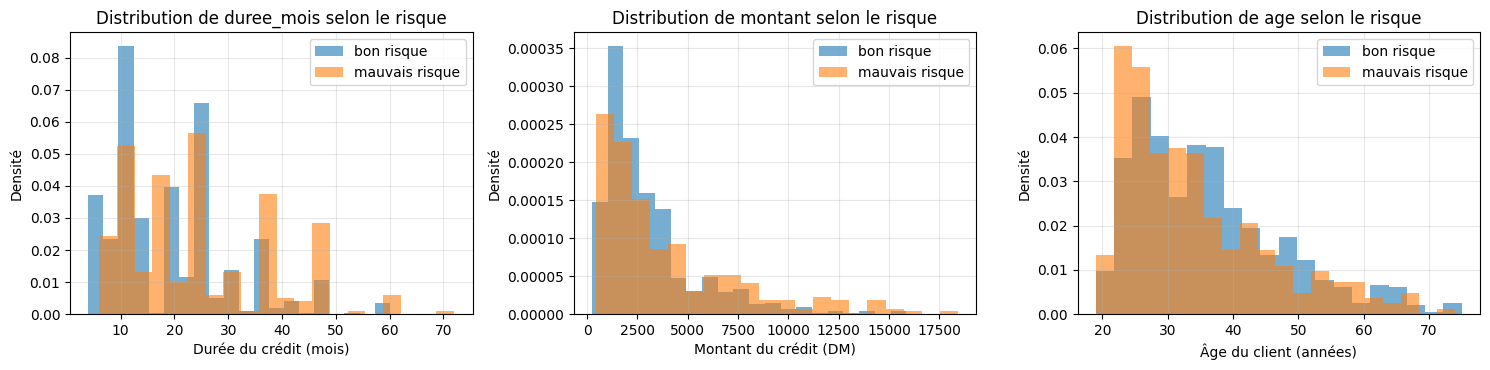

In [8]:
# Graphique 1 : distributions des trois variables numériques principales
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, (col, xl) in zip(ax, [('duree_mois', 'Durée du crédit (mois)'),
                             ('montant', 'Montant du crédit (DM)'),
                             ('age', 'Âge du client (années)')]):
    for v, nom in [(0, 'bon risque'), (1, 'mauvais risque')]:
        a.hist(df.loc[df[CIBLE] == v, col], bins=20, alpha=.6, density=True, label=nom)
    a.set_title(f'Distribution de {col} selon le risque'); a.set_xlabel(xl); a.set_ylabel('Densité'); a.legend()
plt.tight_layout(); plt.show()

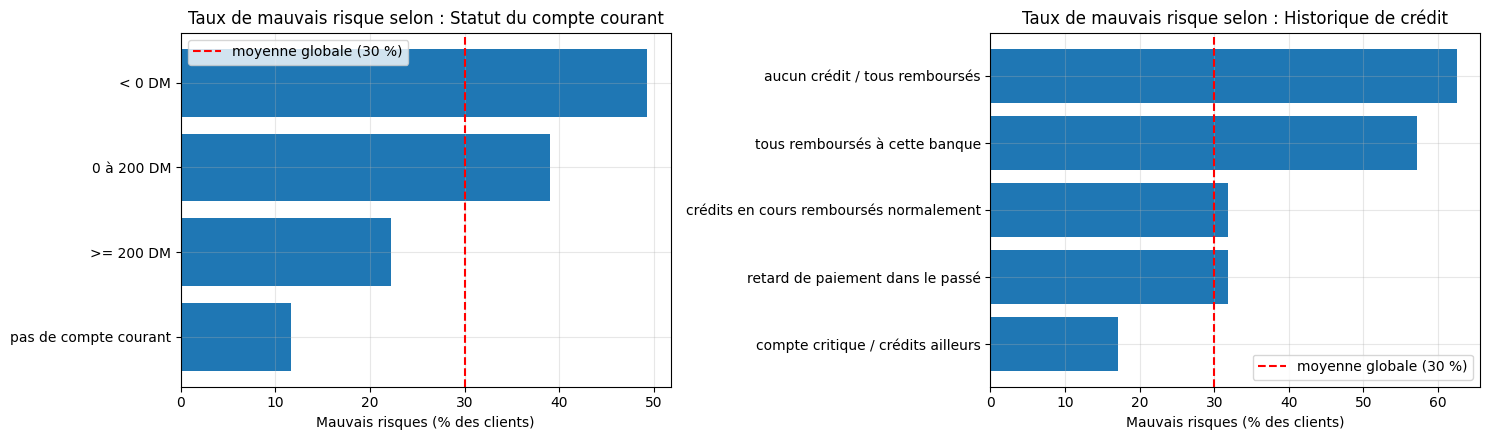

In [9]:
# Graphique 2 : taux de mauvais risque par modalité (deux variables catégorielles)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, col, titre in [(ax[0], 'statut_compte', 'Statut du compte courant'),
                      (ax[1], 'historique_credit', 'Historique de crédit')]:
    t = df.groupby(col)[CIBLE].mean().sort_values() * 100
    a.barh(t.index, t.values)
    a.axvline(100 * df[CIBLE].mean(), color='red', ls='--', label='moyenne globale (30 %)')
    a.set_title(f'Taux de mauvais risque selon : {titre}'); a.set_xlabel('Mauvais risques (% des clients)')
    a.set_ylabel(''); a.legend()
plt.tight_layout(); plt.show()

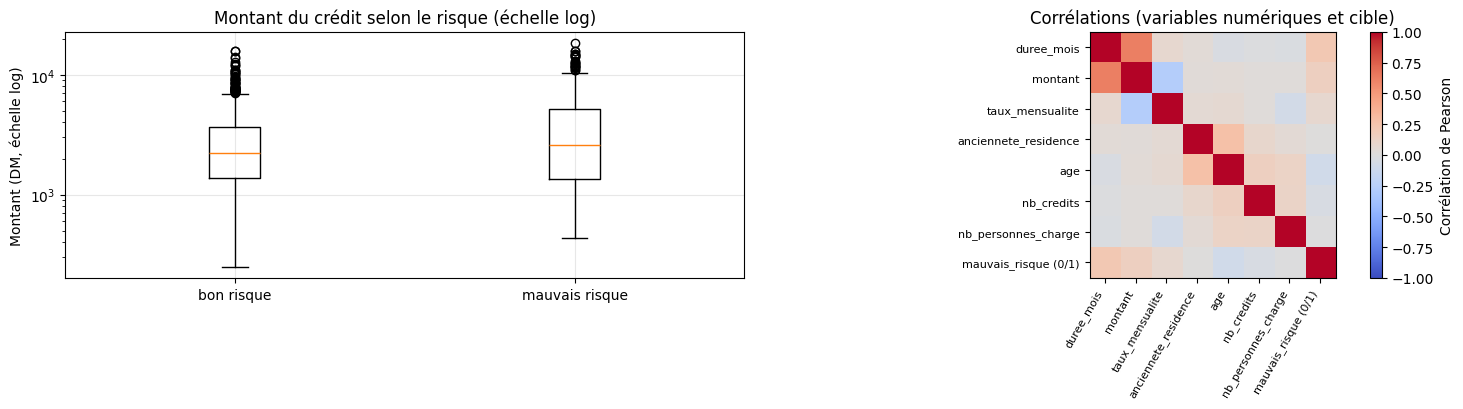

In [10]:
# Graphique 3 : montant selon le risque (boîtes à moustaches, échelle logarithmique)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
ax[0].boxplot([df.loc[df[CIBLE] == 0, 'montant'], df.loc[df[CIBLE] == 1, 'montant']])
ax[0].set_xticklabels(['bon risque', 'mauvais risque'])
ax[0].set_yscale('log'); ax[0].set_title('Montant du crédit selon le risque (échelle log)')
ax[0].set_ylabel('Montant (DM, échelle log)')

# Graphique 4 : matrice de corrélation des variables numériques
corr = df[num + [CIBLE]].corr()
im = ax[1].imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax[1].set_xticks(range(len(corr))); ax[1].set_xticklabels(corr.columns, rotation=60, ha='right', fontsize=8)
ax[1].set_yticks(range(len(corr))); ax[1].set_yticklabels(corr.columns, fontsize=8)
ax[1].set_title('Corrélations (variables numériques et cible)'); ax[1].grid(False)
plt.colorbar(im, ax=ax[1], label='Corrélation de Pearson')
plt.tight_layout(); plt.show()

**Lecture.** Les mauvais risques demandent en moyenne des crédits plus longs et plus élevés ; le statut du compte courant et l'historique de crédit font fortement varier le taux de défaut (les clients sans compte courant sont les moins risqués dans cette base). Les corrélations linéaires entre variables numériques restent modérées (la plus forte lie durée et montant, ce qui est logique), donc pas de redondance gênante pour les modèles utilisés.

## 4. Préparation des données

Chaque choix est justifié ; aucune statistique n'est calculée sur le jeu de test.

In [11]:
# 1) Nettoyage : suppression des colonnes inutilisables
#    - 'n°'   : identifiant sans valeur prédictive
#    - 'risque': libellé texte de la cible -> fuite de données si on le garde
data = df.drop(columns=['n°', 'risque']).copy()

# 2) Valeurs manquantes : aucune (section 3.2) -> pas d'imputation

# 3) Création de variables (calcul ligne par ligne, donc sans fuite)
data['mensualite_estimee'] = data['montant'] / data['duree_mois']   # DM par mois : charge de remboursement
data['log_montant'] = np.log1p(data['montant'])                      # réduit l'asymétrie du montant

# 4) Encodage : indicatrices (one-hot) pour les 13 variables catégorielles
y = data[CIBLE]
X = pd.get_dummies(data.drop(columns=[CIBLE]), dtype=float)
print('Variables après encodage :', X.shape[1])

# 5) Découpage stratifié 80 % / 20 % (la part de mauvais risques est conservée)
Xc_ent, Xc_test, yc_ent, yc_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=GRAINE)
print('Entraînement :', Xc_ent.shape, '| part mauvais risques : %.1f %%' % (100 * yc_ent.mean()))
print('Test         :', Xc_test.shape, '| part mauvais risques : %.1f %%' % (100 * yc_test.mean()))

Variables après encodage : 63
Entraînement : (800, 63) | part mauvais risques : 30.0 %
Test         : (200, 63) | part mauvais risques : 30.0 %


**Justifications**
- **Nettoyage :** `n°` n'a aucun pouvoir prédictif ; `risque` est la cible recopiée en texte (fuite de données).
- **Valeurs manquantes :** aucune, donc pas d'imputation.
- **Création de variables :** `mensualite_estimee = montant / durée` approche la charge mensuelle de remboursement (notion centrale en crédit) ; `log_montant` atténue l'asymétrie du montant.
- **Encodage :** les modalités n'ont pas d'ordre naturel fiable (objet du crédit, statut personnel…) ; le *one-hot* évite d'imposer un ordre artificiel. Il ne calcule aucune statistique, donc l'appliquer avant le découpage ne crée pas de fuite.
- **Découpage :** stratifié pour garder 30 % de mauvais risques dans l'entraînement et le test ; le test n'est utilisé qu'une fois, en section 7.
- **Mise à l'échelle :** *nécessaire* pour la régression logistique (régularisation et convergence), le KNN (distances) et le SVM RBF (noyau basé sur des distances) : sans elle, `montant` (en milliers de DM) écraserait les indicatrices 0/1. *Inutile* pour les arbres, la forêt, les boosting et Naive Bayes gaussien (séparations par seuils ou lois par variable, invariantes à l'échelle). Elle est faite **dans un `Pipeline`** : la moyenne et l'écart-type sont donc appris sur l'entraînement uniquement (et sur chaque pli en validation croisée).

## 5. Algorithmes

Neuf algorithmes de classification du TP sont entraînés sur le **jeu d'entraînement uniquement**, avec les hyperparamètres du support (non optimisés). Pour chacun : la question ciblée du TP et une réponse courte.

In [12]:
modeles = {}

### 5.1 Régression logistique

**Question ciblée :** Comment interpréter une probabilité prédite et ajuster le seuil de classification ?

Elle modélise la probabilité de défaut par une fonction sigmoïde d'une combinaison linéaire des variables. Une probabilité de 0,35 signifie « 35 % de risque estimé » ; le seuil par défaut (0,5) peut être abaissé pour détecter plus de mauvais payeurs au prix de plus de refus (voir 7.3). `C` règle la régularisation (petit C = modèle plus contraint).

In [13]:
from sklearn.linear_model import LogisticRegression
modeles['Régression logistique'] = make_pipeline(StandardScaler(),
    LogisticRegression(C=.2, max_iter=1500, random_state=GRAINE)).fit(Xc_ent, yc_ent)

### 5.2 KNN

**Question ciblée :** Quel est l'effet d'une distance normalisée et du nombre de voisins ?

Un client est classé selon ses k plus proches voisins. Sans normalisation, la distance serait dominée par le montant ; avec `weights='distance'`, les voisins proches pèsent plus. Un k petit donne un modèle instable, un k grand le lisse (et favorise la classe majoritaire).

In [14]:
from sklearn.neighbors import KNeighborsClassifier
modeles['KNN'] = make_pipeline(StandardScaler(),
    KNeighborsClassifier(n_neighbors=9, weights='distance')).fit(Xc_ent, yc_ent)

### 5.3 Naive Bayes

**Question ciblée :** Quelle hypothèse d'indépendance conditionnelle est faite par Naive Bayes ?

Les variables sont supposées **indépendantes entre elles sachant la classe**, et gaussiennes dans chaque classe. L'hypothèse est fausse ici (durée et montant sont liés) mais le modèle reste souvent compétitif et très rapide.

In [15]:
from sklearn.naive_bayes import GaussianNB
modeles['Naive Bayes'] = GaussianNB(var_smoothing=1e-8).fit(Xc_ent, yc_ent)

### 5.4 Arbre de décision

**Question ciblée :** Comment calculer l'impureté de Gini et choisir une séparation ?

Gini = 1 − p₀² − p₁² ; à chaque nœud, l'arbre retient la séparation qui réduit le plus l'impureté pondérée des deux nœuds fils. `max_depth=3` et `min_samples_leaf=5` limitent le sur-apprentissage et gardent un arbre lisible.

In [16]:
from sklearn.tree import DecisionTreeClassifier
modeles['Arbre de décision'] = DecisionTreeClassifier(max_depth=3, min_samples_leaf=5,
    random_state=GRAINE).fit(Xc_ent, yc_ent)

### 5.5 Forêt aléatoire

**Question ciblée :** Pourquoi une forêt est-elle généralement moins instable qu'un arbre seul ?

Elle moyenne de nombreux arbres entraînés sur des échantillons bootstrap et des sous-ensembles de variables : leurs erreurs, peu corrélées, se compensent, ce qui réduit la variance.

In [17]:
from sklearn.ensemble import RandomForestClassifier
modeles['Forêt aléatoire'] = RandomForestClassifier(n_estimators=110, max_depth=6,
    random_state=GRAINE, n_jobs=-1).fit(Xc_ent, yc_ent)

### 5.6 SVM

**Question ciblée :** À quoi servent les vecteurs de support et le paramètre C ?

Les vecteurs de support sont les clients proches de la frontière : eux seuls la définissent. `C` arbitre entre marge large (C petit, tolérance aux erreurs) et classement strict des points d'entraînement (C grand, risque de sur-apprentissage).

In [18]:
from sklearn.svm import SVC
modeles['SVM'] = make_pipeline(StandardScaler(),
    SVC(kernel='rbf', C=2., gamma='scale')).fit(Xc_ent, yc_ent)

### 5.7 Gradient Boosting

**Question ciblée :** Comment corriger progressivement les erreurs de classification ?

Des arbres peu profonds sont ajoutés l'un après l'autre ; chacun est entraîné sur le gradient de l'erreur (ce que l'ensemble précédent prédit mal) et sa contribution s'ajoute à la prédiction.

In [19]:
from sklearn.ensemble import HistGradientBoostingClassifier
modeles['Gradient Boosting'] = HistGradientBoostingClassifier(max_iter=100, max_leaf_nodes=10,
    random_state=GRAINE).fit(Xc_ent, yc_ent)

### 5.8 AdaBoost

**Question ciblée :** Comment AdaBoost repondère-t-il les exemples difficiles ?

À chaque itération, les clients mal classés voient leur poids augmenter, ce qui force le modèle suivant à s'y concentrer ; les modèles sont combinés avec un vote pondéré par leur qualité. `learning_rate` réduit l'influence de chaque étape.

In [20]:
from sklearn.ensemble import AdaBoostClassifier
modeles['AdaBoost'] = AdaBoostClassifier(n_estimators=90, learning_rate=.7,
    random_state=GRAINE).fit(Xc_ent, yc_ent)

### 5.9 XGBoost

**Question ciblée :** Quel est le rôle de la régularisation et du learning_rate dans XGBoost ?

XGBoost est un gradient boosting avec pénalisation de la complexité des arbres (L1/L2 sur les poids des feuilles, coût par feuille). `learning_rate` (ici 0,09) réduit l'apport de chaque arbre : plus il est petit, plus il faut d'arbres, mais plus la généralisation est stable.

In [22]:
# Sous Colab, xgboost est déjà installé ; sinon : !pip install xgboost
try:
    from xgboost import XGBClassifier

    # Nettoyage des noms de colonnes contenant des caractères spéciaux pour XGBoost
    import re
    regex = re.compile(r"[\[\]<]", re.UNICODE)

    Xc_ent_clean = Xc_ent.rename(columns=lambda x: regex.sub("_", x))
    Xc_test_clean = Xc_test.rename(columns=lambda x: regex.sub("_", x))

    # On ré-entraîne XGBoost avec les données nettoyées
    modeles['XGBoost'] = XGBClassifier(n_estimators=100, max_depth=2, learning_rate=.09,
        random_state=GRAINE, eval_metric='logloss').fit(Xc_ent_clean, yc_ent)

    # On met à jour Xc_ent et Xc_test globalement pour que les étapes suivantes fonctionnent avec XGBoost
    Xc_ent = Xc_ent_clean
    Xc_test = Xc_test_clean
except ImportError:
    print("xgboost n'est pas installé : modèle ignoré (pip install xgboost).")

In [23]:
print(len(modeles), 'modèles entraînés :', list(modeles))

9 modèles entraînés : ['Régression logistique', 'KNN', 'Naive Bayes', 'Arbre de décision', 'Forêt aléatoire', 'SVM', 'Gradient Boosting', 'AdaBoost', 'XGBoost']


## 6. Protocole d'évaluation

1. **Découpage :** 80 % entraînement / 20 % test, stratifié, graine 42 (section 4).
2. **Validation croisée :** 5 plis stratifiés **sur l'entraînement uniquement**, pour comparer les modèles et régler un hyperparamètre sans toucher au test.
3. **Évaluation finale :** une seule fois sur le jeu de test (section 7), au seuil par défaut 0,5, avec F1 (classe mauvais risque), rappel, précision, exactitude et AUC-ROC.
4. **Référence :** règle « tout client = mauvais risque » (F1 ≈ 0,46).
5. **Critère de réussite :** F1 test ≥ 0,55 (fixé en 1.3).

In [24]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)
lignes = []
for nom, m in modeles.items():
    s = cross_val_score(m, Xc_ent, yc_ent, cv=cv, scoring='f1', n_jobs=-1)
    lignes.append({'Algorithme': nom, 'F1 CV (moyenne)': s.mean(), 'F1 CV (écart-type)': s.std()})
tab_cv = pd.DataFrame(lignes).sort_values('F1 CV (moyenne)', ascending=False).reset_index(drop=True)
display(tab_cv.round(3))

,Algorithme,F1 CV (moyenne),F1 CV (écart-type)
0,Gradient Boosting,0.540,0.074
1,Naive Bayes,0.535,0.092
2,SVM,0.509,0.111
3,Régression logistique,0.492,0.100
4,XGBoost,0.487,0.092
5,AdaBoost,0.463,0.055
6,KNN,0.348,0.098
7,Arbre de décision,0.330,0.151
8,Forêt aléatoire,0.293,0.069


### 6.1 Variation d'un hyperparamètre (validation croisée sur l'entraînement)
Effet de `C` (régularisation) pour la régression logistique et de `k` pour le KNN.

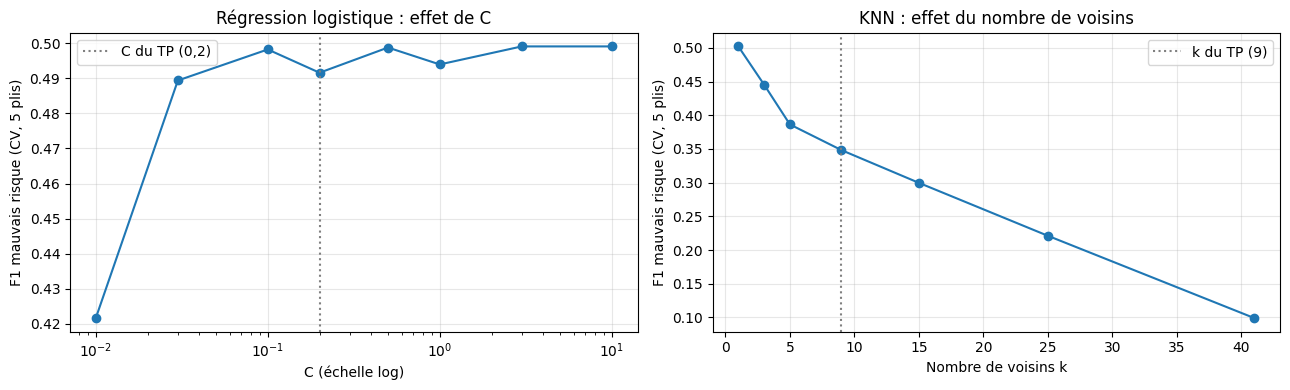

Meilleur C : 3 | meilleur k : 1


In [25]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

Cs = [0.01, 0.03, 0.1, 0.2, 0.5, 1, 3, 10]
sc = [cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=3000, random_state=GRAINE)),
                      Xc_ent, yc_ent, cv=cv, scoring='f1').mean() for c in Cs]
ax[0].semilogx(Cs, sc, marker='o'); ax[0].axvline(.2, color='grey', ls=':', label='C du TP (0,2)')
ax[0].set_title('Régression logistique : effet de C'); ax[0].set_xlabel('C (échelle log)')
ax[0].set_ylabel('F1 mauvais risque (CV, 5 plis)'); ax[0].legend()

ks = [1, 3, 5, 9, 15, 25, 41]
sk = [cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k, weights='distance')),
                      Xc_ent, yc_ent, cv=cv, scoring='f1').mean() for k in ks]
ax[1].plot(ks, sk, marker='o'); ax[1].axvline(9, color='grey', ls=':', label='k du TP (9)')
ax[1].set_title('KNN : effet du nombre de voisins'); ax[1].set_xlabel('Nombre de voisins k')
ax[1].set_ylabel('F1 mauvais risque (CV, 5 plis)'); ax[1].legend()
plt.tight_layout(); plt.show()
print('Meilleur C :', Cs[int(np.argmax(sc))], '| meilleur k :', ks[int(np.argmax(sk))])

## 7. Résultats sur le jeu de test

### 7.1 Comparaison des algorithmes

Référence (tout = mauvais risque) : F1 = 0.462 | exactitude = 0.300


,Algorithme,F1 (mauvais risque),Rappel,Précision,Exactitude,AUC-ROC,Objectif atteint (F1 >= 0.55)
0,Régression logistique,0.625,0.583,0.673,0.790,0.810,oui
1,XGBoost,0.602,0.517,0.721,0.795,0.799,oui
2,Gradient Boosting,0.593,0.533,0.667,0.780,0.773,oui
3,Naive Bayes,0.560,0.583,0.538,0.725,0.785,oui
4,SVM,0.545,0.450,0.692,0.775,0.810,non
5,AdaBoost,0.514,0.450,0.600,0.745,0.782,non
6,KNN,0.483,0.350,0.778,0.775,0.808,non
7,Arbre de décision,0.386,0.283,0.607,0.730,0.716,non
8,Forêt aléatoire,0.380,0.250,0.789,0.755,0.808,non


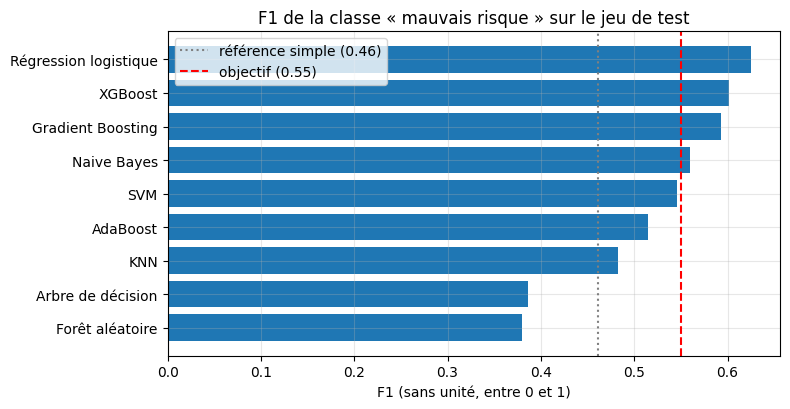

In [27]:
def evaluer(nom, modele):
    # Si le modèle est XGBoost, il utilise les colonnes nettoyées
    # Sinon, pour scikit-learn, on remet les noms de colonnes d'origine avec lesquels ils ont été entraînés
    if nom == 'XGBoost':
        X_eval = Xc_test
    else:
        # On restaure temporairement les noms originels pour scikit-learn
        import re
        X_eval = Xc_test.copy()
        X_eval.columns = X.columns

    pred = modele.predict(X_eval)
    score = modele.predict_proba(X_eval)[:, 1] if hasattr(modele, 'predict_proba') else modele.decision_function(X_eval)
    return {'Algorithme': nom,
            'F1 (mauvais risque)': f1_score(yc_test, pred),
            'Rappel': recall_score(yc_test, pred),
            'Précision': precision_score(yc_test, pred, zero_division=0),
            'Exactitude': accuracy_score(yc_test, pred),
            'AUC-ROC': roc_auc_score(yc_test, score)}

# Référence simple
pred_ref = np.ones(len(yc_test), dtype=int)
F1_REF = f1_score(yc_test, pred_ref)
print('Référence (tout = mauvais risque) : F1 = %.3f | exactitude = %.3f' % (F1_REF, accuracy_score(yc_test, pred_ref)))

tab = pd.DataFrame([evaluer(n, m) for n, m in modeles.items()]).sort_values('F1 (mauvais risque)', ascending=False).reset_index(drop=True)
tab['Objectif atteint (F1 >= %.2f)' % OBJECTIF_F1] = np.where(tab['F1 (mauvais risque)'] >= OBJECTIF_F1, 'oui', 'non')
display(tab.round(3))

plt.figure(figsize=(8, 4.2))
plt.barh(tab['Algorithme'][::-1], tab['F1 (mauvais risque)'][::-1])
plt.axvline(F1_REF, color='grey', ls=':', label='référence simple (%.2f)' % F1_REF)
plt.axvline(OBJECTIF_F1, color='red', ls='--', label='objectif (%.2f)' % OBJECTIF_F1)
plt.title('F1 de la classe « mauvais risque » sur le jeu de test'); plt.xlabel('F1 (sans unité, entre 0 et 1)')
plt.legend(); plt.tight_layout(); plt.show()

### 7.2 Matrice de confusion du meilleur modèle

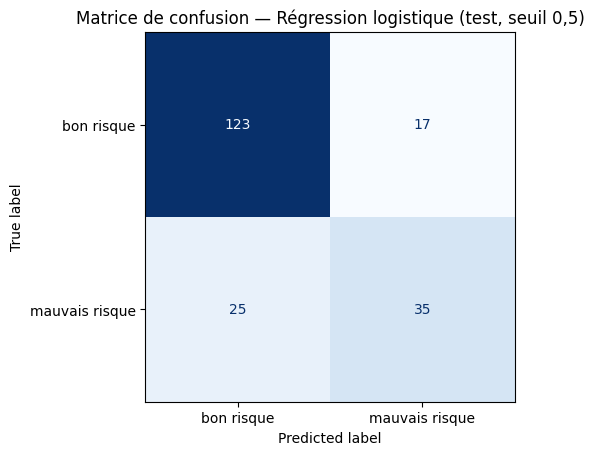

In [30]:
nom_best = tab.loc[0, 'Algorithme']
best = modeles[nom_best]

# Si le meilleur modèle n'est pas XGBoost, on restaure temporairement les colonnes originales pour la prédiction
if nom_best == 'XGBoost':
    X_eval = Xc_test
else:
    X_eval = Xc_test.copy()
    X_eval.columns = X.columns

ConfusionMatrixDisplay(confusion_matrix(yc_test, best.predict(X_eval)),
                       display_labels=['bon risque', 'mauvais risque']).plot(cmap='Blues', colorbar=False)
plt.title(f'Matrice de confusion — {nom_best} (test, seuil 0,5)'); plt.grid(False); plt.show()

### 7.3 Choix du seuil de classification (régression logistique)
Le seuil est choisi sur les **probabilités hors-échantillon de l'entraînement** (validation croisée), puis appliqué une seule fois au test. Cela évite de régler le seuil sur les données de test.

Seuil retenu (F1 maximal en validation croisée) : 0.25


,seuil,précision,rappel,F1,clients refusés (%)
0,0.25,0.515,0.833,0.637,48.5
1,0.30,0.563,0.817,0.667,43.5
2,0.40,0.627,0.700,0.661,33.5
3,0.50,0.673,0.583,0.625,26.0


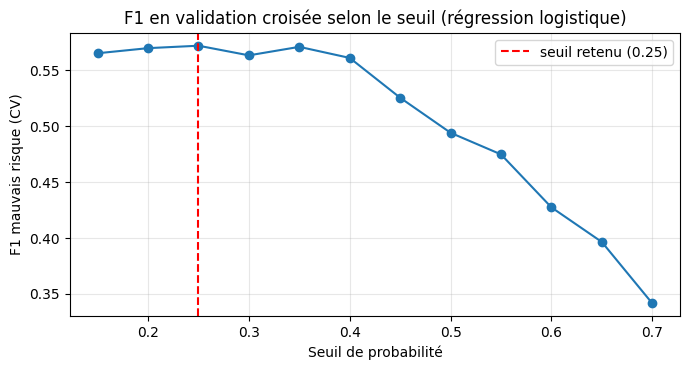

In [32]:
logit = modeles['Régression logistique']
p_oof = cross_val_predict(logit, Xc_ent, yc_ent, cv=cv, method='predict_proba')[:, 1]
seuils = np.arange(0.15, 0.71, 0.05)
f1_oof = [f1_score(yc_ent, (p_oof >= s).astype(int)) for s in seuils]
seuil_opt = float(seuils[int(np.argmax(f1_oof))])
print('Seuil retenu (F1 maximal en validation croisée) : %.2f' % seuil_opt)

# On restaure temporairement les noms originaux des colonnes pour la Régression logistique
Xc_test_orig = Xc_test.copy()
Xc_test_orig.columns = X.columns

proba_test = logit.predict_proba(Xc_test_orig)[:, 1]
lignes = []
for s in sorted(set([0.3, 0.4, 0.5, seuil_opt])):
    p = (proba_test >= s).astype(int)
    lignes.append({'seuil': round(s, 2), 'précision': precision_score(yc_test, p, zero_division=0),
                   'rappel': recall_score(yc_test, p), 'F1': f1_score(yc_test, p),
                   'clients refusés (%)': 100 * p.mean()})
display(pd.DataFrame(lignes).round(3))

plt.figure(figsize=(7, 3.8))
plt.plot(seuils, f1_oof, marker='o'); plt.axvline(seuil_opt, color='red', ls='--', label=f'seuil retenu ({seuil_opt:.2f})')
plt.title('F1 en validation croisée selon le seuil (régression logistique)')
plt.xlabel('Seuil de probabilité'); plt.ylabel('F1 mauvais risque (CV)'); plt.legend(); plt.tight_layout(); plt.show()

Abaisser le seuil augmente le rappel (plus de mauvais payeurs détectés) mais refuse davantage de bons clients. Le seuil réellement adapté dépend du **coût d'un défaut par rapport au coût d'un refus**, que la base ne fournit pas.

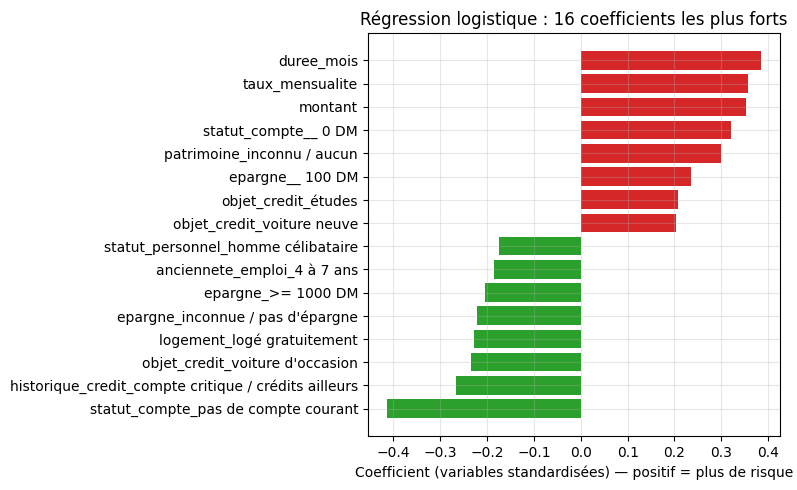

In [33]:
# Variables les plus influentes (coefficients standardisés de la régression logistique)
coef = pd.Series(logit[-1].coef_[0], index=Xc_ent.columns).sort_values()
sel = pd.concat([coef.head(8), coef.tail(8)])
plt.figure(figsize=(8, 5))
plt.barh(sel.index, sel.values, color=['tab:green' if v < 0 else 'tab:red' for v in sel.values])
plt.title('Régression logistique : 16 coefficients les plus forts'); plt.xlabel('Coefficient (variables standardisées) — positif = plus de risque')
plt.tight_layout(); plt.show()

## 8. Analyse critique

*Les chiffres cités ci-dessous correspondent à l'exécution avec `GRAINE = 42` sur les algorithmes scikit-learn ; après avoir exécuté le notebook (avec XGBoost), relisez le tableau 7.1 et ajustez le texte si le classement change.*

**Ce que montrent les résultats**
- Au seuil par défaut (0,5), deux algorithmes atteignent l'objectif de F1 ≥ 0,55 sur le test : la régression logistique (≈ 0,63) et Naive Bayes (≈ 0,56). Gradient Boosting (≈ 0,547) et SVM (≈ 0,545) sont juste en dessous ; l'arbre et la forêt restent loin (≈ 0,38).
- Le rappel est faible pour la plupart des modèles (souvent 25 % à 58 %) : à 0,5, ils manquent beaucoup de mauvais payeurs. Pourtant l'AUC-ROC est proche de 0,80 pour la régression logistique, le SVM, le KNN et la forêt : ces modèles **savent classer** les clients par risque, c'est surtout le seuil de 0,5 qui est mal adapté à une classe minoritaire de 30 %. C'est pourquoi la forêt a un F1 bas malgré une bonne AUC.
- Le seuil choisi en validation croisée (≈ 0,25) fait monter le rappel de la régression logistique vers 0,8 mais conduit à refuser près de la moitié des clients (section 7.3) : le bon seuil dépend du coût d'un défaut comparé au coût d'un client refusé à tort, que la base ne donne pas.

**Fiabilité du classement**
- Le classement en validation croisée (Gradient Boosting ≈ 0,54, Naive Bayes ≈ 0,54, SVM ≈ 0,51, régression logistique ≈ 0,49) n'est pas celui du test (régression logistique en tête). Les écarts-types en validation croisée (0,07 à 0,15) et le test de seulement 60 mauvais risques montrent que **les écarts entre les quatre premiers ne sont pas significatifs**. Désigner un « meilleur » algorithme sur ce seul test serait trop optimiste, d'autant que l'objectif est atteint de justesse.
- Le seuil de 0,55 est donc franchi par deux modèles sur un seul découpage ; il n'est pas démontré qu'il le serait avec un autre tirage.

**Sensibilité aux hyperparamètres (6.1)**
- Régression logistique : le F1 est presque plat pour C entre 0,1 et 10 (≈ 0,49–0,50) ; seule une régularisation très forte (C = 0,01) dégrade le modèle (≈ 0,42), car il se rapproche d'une prédiction de la classe majoritaire.
- KNN : le F1 baisse nettement quand k augmente (≈ 0,50 pour k = 1, ≈ 0,10 pour k = 41), parce que les voisins majoritaires « bons risques » l'emportent. Le k = 1 le plus performant est aussi le plus instable (sur-apprentissage) ; il faudrait une autre métrique ou un seuil ajusté pour le départager.

**Interprétation des variables (régression logistique)**
- Les facteurs associés à plus de risque : durée, mensualité en % du revenu, montant, compte courant < 0 DM, épargne < 100 DM ; l'absence de compte courant est associée à moins de risque. Ce sont des **associations**, pas des causes : l'absence de compte courant dans cette base peut refléter la manière dont les clients ont été sélectionnés.

**Limites**
- Petit échantillon (1 000 clients), base ancienne en Deutsche Mark, aucune dimension temporelle (pas de test hors période).
- Hyperparamètres du TP, non optimisés ; un réglage sur validation pourrait changer le classement.
- Pas de matrice de coûts des erreurs.
- Variables sensibles : `statut_personnel` (sexe et situation familiale), `age` et `travailleur_etranger` sont dans le modèle. Dans un vrai scoring de crédit, leur usage poserait des problèmes de non-discrimination (légaux et éthiques) ; il faudrait les retirer et vérifier l'équité du modèle.
- Les montants de la base ne sont pas ajustés de l'inflation ni convertis en monnaie actuelle.


## 9. Conclusion

**Réponse à la problématique.** Oui, les caractéristiques connues à la demande permettent de repérer les mauvais risques bien mieux que le hasard : l'AUC-ROC atteint environ 0,81 pour plusieurs modèles, et deux algorithmes dépassent l'objectif fixé (F1 ≥ 0,55 au seuil de 0,5) : la régression logistique (≈ 0,63) et Naive Bayes (≈ 0,56). Gradient Boosting et SVM le manquent de très peu, et l'arbre seul ainsi que la forêt sont nettement en dessous au seuil de 0,5.

**Recommandation.** La régression logistique est un bon candidat : performante sur le test, AUC élevée, stable en fonction de C, et surtout **interprétable** (coefficients lisibles par un chargé de clientèle), ce qui compte en finance. Son seuil de décision doit être fixé en fonction du coût d'un défaut et du coût d'un refus.

**Prudence.** L'objectif est atteint de justesse sur un test de 200 clients ; les différences entre les quatre premiers algorithmes ne sont pas significatives et le classement diffère entre validation croisée et test. Les pistes pour la suite sont une validation croisée répétée, un réglage des hyperparamètres, une matrice de coûts, et le retrait des variables sensibles avant tout usage réel.


## 10. Références
- Hofmann, H. (1994). *Statlog (German Credit Data)*. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data
- Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research, 12, 2825–2830. Documentation : https://scikit-learn.org/stable/
- scikit-learn, *Real world datasets* : https://scikit-learn.org/stable/datasets/real_world.html
- Breiman, L. (2001). *Random Forests*. Machine Learning, 45(1), 5–32.
- Freund, Y. & Schapire, R. (1997). *A decision-theoretic generalization of on-line learning and an application to boosting*. Journal of Computer and System Sciences, 55(1), 119–139.
- Chen, T. & Guestrin, C. (2016). *XGBoost: A Scalable Tree Boosting System*. Proceedings of KDD 2016, 785–794.
- Cortes, C. & Vapnik, V. (1995). *Support-vector networks*. Machine Learning, 20, 273–297.
- Hastie, T., Tibshirani, R. & Friedman, J. (2009). *The Elements of Statistical Learning* (2e éd.). Springer.

## 11. Déclaration des ressources et outils d'IA

| Rubrique | Déclaration |
|---|---|
| Outil d'IA utilisé | Claude (Anthropic) |
| Usage | Aide à la structuration du notebook, à la rédaction du code Python (préparation, modèles, évaluation) et à la rédaction des commentaires |
| Ressources hors IA | Support de TP (« Tp_ML_a_suivre »), énoncé et annexes du devoir, documentation scikit-learn, données *German Credit* fournies |
| Vérifications personnelles | *À compléter : ce que vous avez relu, exécuté, compris et modifié vous-même* |
| Parties rédigées sans IA | *À compléter* |

*À adapter à la rédaction exacte de la section 11 de l'énoncé et à votre usage réel avant de rendre le notebook.*